# 01. Exploratory Data Analysis & Dataset Audit
### Project 12: Everyday Waste Sorting via Manual Descriptors vs. Transfer Learning
**Course:** Applied Machine Learning & Deep Learning (AML-DL)  
**Dataset:** TrashNet (Stanford CS229 Benchmark - Gary Thung & Mindy Yang)

---
## 1. Executive Summary & Objective
This notebook performs rigorous Exploratory Data Analysis (EDA) on the TrashNet dataset. The primary objectives are:
1. Audit image resolutions, aspect ratios, and color channel distributions.
2. Investigate class imbalance (majority `paper` vs. minority `trash`).
3. Verify deterministic train / validation / test splits to prevent data leakage.
4. Visualize visual sample montages across all 6 material classes.


In [4]:
import sys
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

# Ensure repository root in path
REPO_ROOT = Path("..").resolve()
SPLITS_DIR = REPO_ROOT / "splits"
DATA_DIR = REPO_ROOT / "data" / "dataset-resized"

# Style configuration
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.size"] = 11


## 2. Load Split Manifests & Class Metadata
We load the deduplicated manifests generated by our stratified 70/15/15 splitting procedure (`src/data_split.py`).


In [5]:
with open(SPLITS_DIR / "classes.json", "r") as f:
    meta = json.load(f)
class_names = meta["class_names"]
label_map = meta["label_map"]

train_df = pd.read_csv(SPLITS_DIR / "train.csv")
val_df = pd.read_csv(SPLITS_DIR / "val.csv")
test_df = pd.read_csv(SPLITS_DIR / "test.csv")

print(f"Total Unique Images: {len(train_df) + len(val_df) + len(test_df)}")
print(f"Train set: {len(train_df)} ({len(train_df)/(len(train_df)+len(val_df)+len(test_df))*100:.1f}%)")
print(f"Validation set: {len(val_df)} ({len(val_df)/(len(train_df)+len(val_df)+len(test_df))*100:.1f}%)")
print(f"Test set: {len(test_df)} ({len(test_df)/(len(train_df)+len(val_df)+len(test_df))*100:.1f}%)")


Total Unique Images: 2519
Train set: 1763 (70.0%)
Validation set: 378 (15.0%)
Test set: 378 (15.0%)


## 3. Class Distribution & Imbalance Audit
In real-world municipal waste, class distribution is highly skewed. Let us analyze the distribution across splits.


,Class,Train_Count,Val_Count,Test_Count,Total_Count,Percentage
0,cardboard,282,60,61,403,16.00
1,glass,351,75,75,501,19.89
2,metal,286,62,61,409,16.24
3,paper,412,88,89,589,23.38
4,plastic,336,72,72,480,19.06
5,trash,96,21,20,137,5.44


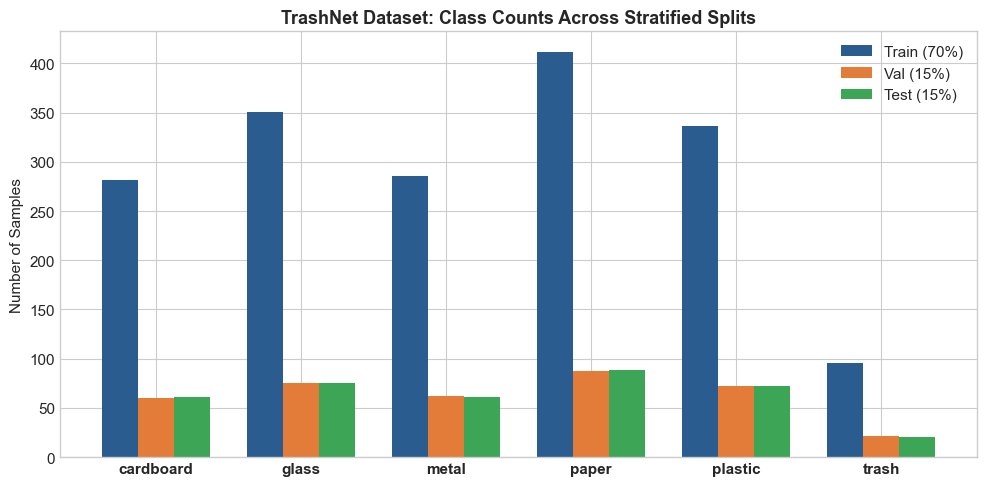

In [6]:
split_summary = pd.read_csv(REPO_ROOT / "results" / "metrics" / "dataset_split_summary.csv")
display(split_summary)

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(class_names))
w = 0.25

ax.bar(x - w, split_summary["Train_Count"], width=w, label="Train (70%)", color="#2b5c8f")
ax.bar(x, split_summary["Val_Count"], width=w, label="Val (15%)", color="#e27c38")
ax.bar(x + w, split_summary["Test_Count"], width=w, label="Test (15%)", color="#3da556")

ax.set_xticks(x)
ax.set_xticklabels(class_names, fontweight="bold")
ax.set_ylabel("Number of Samples")
ax.set_title("TrashNet Dataset: Class Counts Across Stratified Splits", fontsize=13, fontweight="bold")
ax.legend()
plt.tight_layout()
plt.show()


### Key Observations & Empirical Significance:
* **Severe Class Imbalance:** The majority class (`paper`: 589 samples, 23.4%) has more than **$4.3\times$** the samples of the minority class (`trash`: 137 samples, 5.4%). 
* **Stratification Integrity:** The 70% Train, 15% Validation, and 15% Test proportions are preserved identically across all 6 classes, preventing sampling bias.
* **Metric Selection Justification:** Because of this imbalance, standard Accuracy can be misleading. **Macro F1-Score** and **Per-Class Recall** must be used as primary evaluation metrics so the minority `trash` class is evaluated with equal weight.


## 4. Image Resolution & Aspect Ratio Verification
We sample 50 images per class to verify image dimensions and color mode integrity.


In [7]:
resolutions = []
modes = []

for _, row in train_df.sample(200, random_state=42).iterrows():
    img_path = REPO_ROOT / row["filepath"]
    with Image.open(img_path) as img:
        resolutions.append(f"{img.width}x{img.height}")
        modes.append(img.mode)

res_counts = pd.Series(resolutions).value_counts()
mode_counts = pd.Series(modes).value_counts()

print("Observed Resolutions:")
print(res_counts)
print("Color Modes Observed:")
print(mode_counts)


Observed Resolutions:
512x384    200
Name: count, dtype: int64
Color Modes Observed:
RGB    200
Name: count, dtype: int64


## 5. Visual Sample Montage Across Material Classes
Visual inspection of representative objects across all 6 categories.


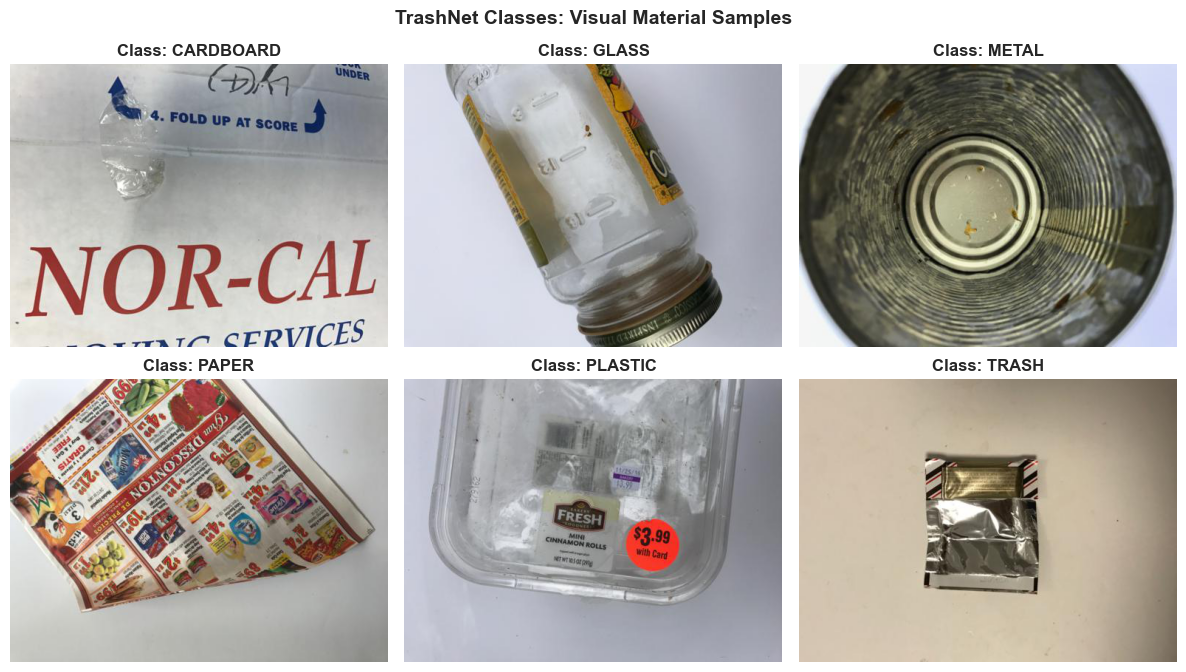

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
axes = axes.flatten()

for idx, c in enumerate(class_names):
    sample_path = REPO_ROOT / train_df[train_df["class_name"] == c].iloc[0]["filepath"]
    with Image.open(sample_path) as img:
        axes[idx].imshow(img)
    axes[idx].set_title(f"Class: {c.upper()}", fontweight="bold", fontsize=12)
    axes[idx].axis("off")

plt.suptitle("TrashNet Classes: Visual Material Samples", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


### Key Observations & Empirical Significance:
* **Controlled Lab Setting:** All samples were captured under relatively clean, centered conditions against consistent white/neutral foam board backgrounds (Stanford CS229 benchmark).
* **High Intra-Class Variance:** Even within a single class (e.g., `plastic`), items range from transparent PET water bottles to opaque HDPE jugs and colored plastic cups.
* **Cross-Class Ambiguity:** Clear transparent plastic cups visually mimic clear glass jars; white paper napkins share high visual similarity with thin white plastic bags.
